# Figs. 3, 4, and 6: background and Snowball threshold CO$_2$

In [1]:
from helpers import *
import pandas as pd
from matplotlib.lines import Line2D

VARIANTS = ["default", "oht_relaxation_1yr"]
VARIANT_LABELS = {"default": "No OHT", "oht_relaxation_1yr": "Fast OHT"}
VARIANT_LINESTYLES = {"default": "-", "oht_relaxation_1yr": "--"}

stats_by_variant_topo = {v: {topo: compute_stats(v, topo) for topo in TOPOS} for v in VARIANTS}

TOPO_COLORS = {key: color for key, _, color in TOPOS_SERIES}

def topo_handles():
    return [Line2D([0], [0], color=color, ls="-", label=label) for _, label, color in TOPOS_SERIES]

def delta_n(stats):
    # N_b - N_s [Emol]
    return carbon_inventory(stats["background"]["co2"]) - carbon_inventory(stats["snowball"]["co2"])

def ns_over_nb(stats):
    # N_s/N_b
    return np.sqrt(stats["snowball"]["co2"] / stats["background"]["co2"])

### Number of equilibrated simulations

In [2]:
run_counts = pd.DataFrame({VARIANT_LABELS[v]: {topo: sum(len(g["co2s"]) for g in load_grid(v, topo).values()) for topo in TOPOS}
                           for v in VARIANTS})
run_counts["Total"] = run_counts.sum(axis=1)
run_counts.loc["Total"] = run_counts.sum()
print(run_counts)

             No OHT  Fast OHT  Total
0Ma            1011       944   1955
0Ma_flat        855       830   1685
300Ma           802       795   1597
300Ma_flat      799       787   1586
720Ma_Mer21     771       824   1595
720Ma_Li23      818       732   1550
Total          5056      4912   9968


### Fig. 3: background and Snowball threshold CO$_2$ vs. time

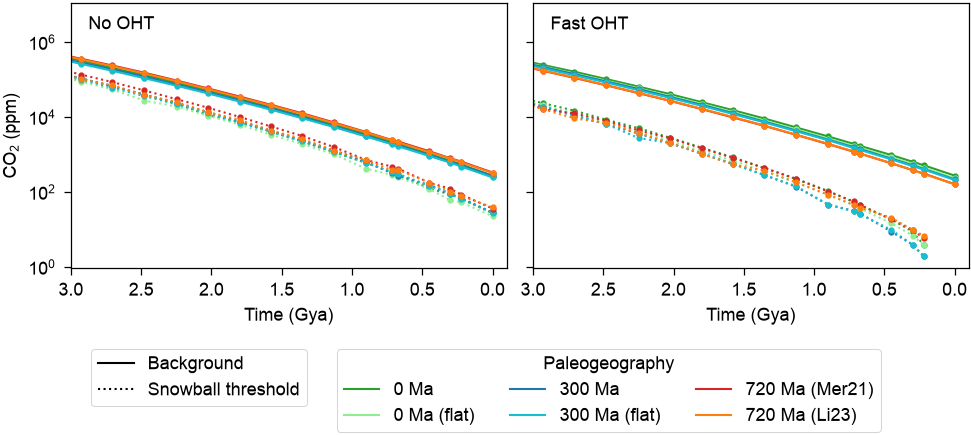

In [3]:
fig, axes = plt.subplots(1, len(VARIANTS), figsize=(FULL_WIDTH, ROW_HEIGHT), sharey=True)

for ax, v in zip(axes, VARIANTS):
    for topo in TOPOS:
        stats = stats_by_variant_topo[v][topo]
        t = stats["age"]
        ax.plot(t, stats["background"]["co2"], color=TOPO_COLORS[topo], ls="-", marker="o", ms=2)
        ax.plot(t, stats["snowball"]["co2"], color=TOPO_COLORS[topo], ls=":", marker="o", ms=2)
    ax.set_yscale("log")
    setup_time_ax(ax)
    ax.text(0.04, 0.95, VARIANT_LABELS[v], transform=ax.transAxes, va="top")

axes[0].set_ylabel("CO$_2$ (ppm)")
plt.tight_layout()

style_handles = [
    Line2D([0], [0], color="k", ls="-", label="Background"),
    Line2D([0], [0], color="k", ls=":", label="Snowball threshold"),
]
leg_style = fig.legend(handles=style_handles, loc="upper center", ncol=1)
leg_topo = fig.legend(handles=topo_handles(), title="Paleogeography", loc="upper center", ncol=3)
place_legends_below(fig, [leg_style, leg_topo])

fig.savefig("figs/co2_vs_time.pdf", bbox_inches="tight")
plt.show()

### Fig. 4: Snowball threshold CO$_2$ compared with previous GCM studies

In [4]:
# Snowball threshold CO2 reported by earlier GCM studies, with the paleogeography each used
# (age [Gya], CO2 [ppm], study, configuration, ocean, marker, marker size, paleogeography source);
# marker sizes adjusted by eye so markers look the same size
LITERATURE_THRESHOLDS = [
    (0.57, 100, "Liu et al. 2013",        "Marinoan (570 Ma config)",        "dynamic", (4, 0, 0),  3.5, "D97"),
    (0.59, 130, "Hyde et al. 2000",       "Varanger (supercontinent)",       "slab",    "P",        4,   "D97"),
    (0.65, 120, "Feulner & Kienert 2014", "Marinoan",                        "dynamic", "o",        3.8, "L13"),
    (0.65, 160, "Eberhard et al. 2023",   "Marinoan (M+21 recon.)",          "dynamic", "^",        3.8, "M21"),
    (0.65, 170, "Eberhard et al. 2023",   "Marinoan (L+13 recon.)",          "dynamic", "<",        3.8, "L13"),
    (0.72, 50,  "Liu et al. 2013",        "Sturtian",                        "dynamic", (4, 0, 45), 5,   "L8"),
    (0.72, 100, "Feulner & Kienert 2014", "Sturtian",                        "dynamic", "o",        3.8, "L13"),
    (0.72, 90,  "Eberhard et al. 2023",   "Sturtian (M+21 recon.)",          "dynamic", "^",        3.8, "M21"),
    (0.72, 137, "Eberhard et al. 2023",   "Sturtian (L+13 recon.)",          "dynamic", "<",        3.8, "L13"),
    (0.65, 10,  "Eberhard et al. 2023",   "Marinoan (polar supercontinent)", "dynamic", ">",        3.8, "polar supercont."),
    (0.65, 190, "Eberhard et al. 2023",   "Marinoan (dispersed)",            "dynamic", "v",        3.8, "dispersed"),
    (0.72, 30,  "Eberhard et al. 2023",   "Sturtian (polar supercontinent)", "dynamic", ">",        3.8, "polar supercont."),
    (0.72, 240, "Eberhard et al. 2023",   "Sturtian (dispersed)",            "dynamic", "v",        3.8, "dispersed"),
]
COLOR_BY_SCHEME = {"dynamic": "black", "slab": "gray"}

def literature_legend_handles():
    # one legend entry per study and paleogeography source, ordered oldest to youngest
    seen = {}
    for age, _, study, _, scheme, marker, size, source in LITERATURE_THRESHOLDS:
        sep = "\n" if study == "Eberhard et al. 2023" else " " # wrap the longest labels
        label = f"{study}{sep}({source})"
        if label in seen:
            seen[label] = seen[label][:3] + (max(seen[label][3], age),)
        else:
            seen[label] = (marker, size, COLOR_BY_SCHEME[scheme], age)
    ordered = sorted(seen.items(), key=lambda kv: -kv[1][3])
    return [Line2D([0], [0], color=c, ls="", marker=m, ms=ms, label=l) for l, (m, ms, c, _) in ordered]

def add_literature_thresholds(ax):
    # small x offsets so points at the same age don't overlap
    by_age = {}
    for entry in LITERATURE_THRESHOLDS:
        by_age.setdefault(entry[0], []).append(entry)
    for age, group in by_age.items():
        for i, (_, co2, _, _, scheme, marker, size, _) in enumerate(group):
            jitter = (i - (len(group) - 1) / 2) * 0.02
            ax.plot([age + jitter], [co2], marker=marker, ls="", color=COLOR_BY_SCHEME[scheme], ms=size, alpha=0.7, zorder=5)

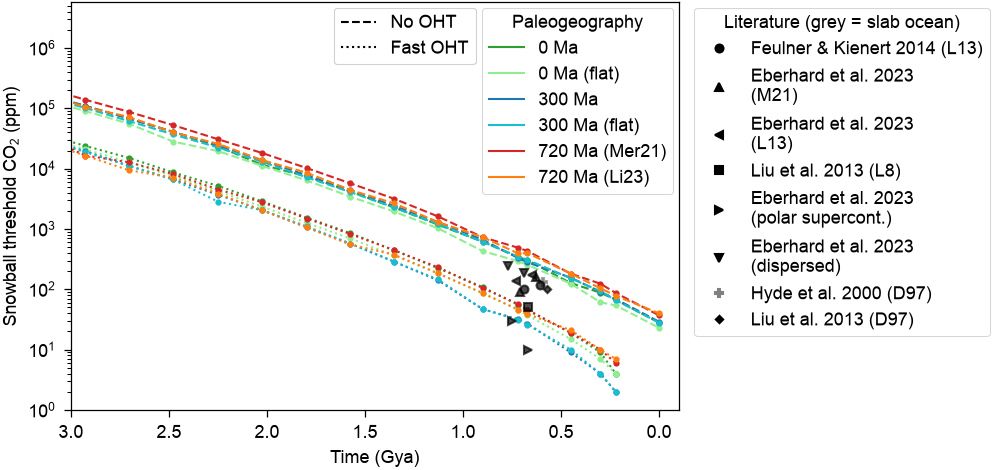

In [5]:
variant_ls = {"default": "--", "oht_relaxation_1yr": ":"}

fig, ax = plt.subplots(figsize=(FULL_WIDTH, MEDIUM_HEIGHT))

for v in VARIANTS:
    for topo in TOPOS:
        stats = stats_by_variant_topo[v][topo]
        t = stats["age"]
        ax.plot(t, stats["snowball"]["co2"], color=TOPO_COLORS[topo], ls=variant_ls[v], marker="o", ms=2)

add_literature_thresholds(ax)
ax.set_yscale("log")
ax.set_ylabel("Snowball threshold CO$_2$ (ppm)")
setup_time_ax(ax)

# literature legend to the right of the axes
leg_lit = fig.legend(handles=literature_legend_handles(), title="Literature (grey = slab ocean)", loc="upper left")
fig.canvas.draw()
w_lit = leg_lit.get_window_extent().transformed(fig.transFigure.inverted()).width
right = 1 - w_lit - 0.02
fig.subplots_adjust(left=0.08, right=right, bottom=0.13, top=0.98)
leg_lit.set_bbox_to_anchor((right + 0.01, 0.98), transform=fig.transFigure)

# OHT and paleogeography legends in the upper right
leg_topo = ax.legend(handles=topo_handles(), title="Paleogeography", loc="upper right")
ax.add_artist(leg_topo)
fig.canvas.draw()
w_topo = leg_topo.get_window_extent().transformed(ax.transAxes.inverted()).width
variant_handles = [Line2D([0], [0], color="k", ls=variant_ls[v], label=VARIANT_LABELS[v]) for v in VARIANTS]
ax.add_artist(ax.legend(handles=variant_handles, loc="upper right", bbox_to_anchor=(1 - w_topo - 0.01, 1)))

fig.savefig("figs/snowball_co2_gcm.pdf", bbox_inches="tight")
plt.show()

### Fig. 6: carbon drawdown $\Delta N$ and normalized Snowball threshold $N_s/N_b$

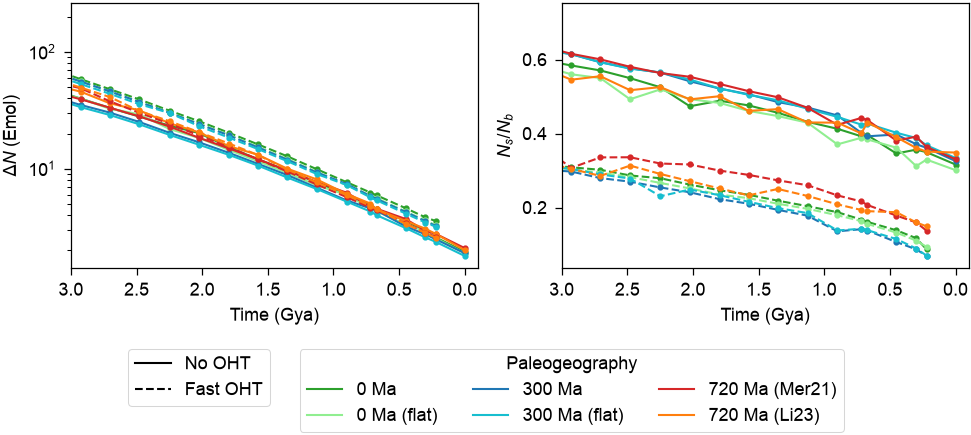

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(FULL_WIDTH, ROW_HEIGHT))

for v in VARIANTS:
    for topo in TOPOS:
        stats = stats_by_variant_topo[v][topo]
        t = stats["age"]
        axes[0].plot(t, delta_n(stats), color=TOPO_COLORS[topo], ls=VARIANT_LINESTYLES[v], marker="o", ms=2)
        axes[1].plot(t, ns_over_nb(stats), color=TOPO_COLORS[topo], ls=VARIANT_LINESTYLES[v], marker="o", ms=2)

axes[0].set_yscale("log")
axes[0].set_ylabel(r"$\Delta N$ (Emol)")
axes[1].set_ylabel(r"$N_s/N_b$")
for ax in axes:
    setup_time_ax(ax)

plt.tight_layout()

variant_handles = [Line2D([0], [0], color="k", ls=VARIANT_LINESTYLES[v], label=VARIANT_LABELS[v]) for v in VARIANTS]
leg_variant = fig.legend(handles=variant_handles, loc="upper center", ncol=1)
leg_topo = fig.legend(handles=topo_handles(), title="Paleogeography", loc="upper center", ncol=3)
place_legends_below(fig, [leg_variant, leg_topo])

fig.savefig("figs/N_metrics.pdf", bbox_inches="tight")
plt.show()

### Values at 720 Ma

In [7]:
TARGET_AGE_MA = 720
ref_stats = stats_by_variant_topo["default"]["0Ma"]

def nearest_index(stats, target_age_ma):
    return np.argmin(np.abs(stats["age"] * 1000 - target_age_ma))

def value_to_age_ma(gsol, values, target_value):
    # age [Ma] at which a curve of values vs. gsol reaches target_value, interpolating in log(value)
    order = np.argsort(values)
    return t_gyr_from_gsol(np.interp(np.log(target_value), np.log(values[order]), gsol[order])) * 1000

def values_at_age(variant, target_age_ma):
    rows = []
    for topo in TOPOS:
        stats = stats_by_variant_topo[variant][topo]
        idx = nearest_index(stats, target_age_ma)
        rows.append({"topo": topo, "background_co2": stats["background"]["co2"][idx],
                     "snowball_co2": stats["snowball"]["co2"][idx], "delta_n_emol": delta_n(stats)[idx]})
    return pd.DataFrame(rows).set_index("topo")

def spread_summary(df):
    curves = {"background_co2": ref_stats["background"]["co2"], "snowball_co2": ref_stats["snowball"]["co2"],
              "delta_n_emol": delta_n(ref_stats)}
    summary = {}
    for col, curve in curves.items():
        lo, hi = df[col].min(), df[col].max()
        summary[col] = {"min_topo": df[col].idxmin(), "min": lo, "max_topo": df[col].idxmax(), "max": hi,
                        "ratio": hi / lo, "equivalent_myr": value_to_age_ma(ref_stats["gsol"], curve, hi)
                                                           - value_to_age_ma(ref_stats["gsol"], curve, lo)}
    return pd.DataFrame(summary).T

print(f"nearest simulated age to {TARGET_AGE_MA} Ma: {ref_stats['age'][nearest_index(ref_stats, TARGET_AGE_MA)] * 1000:.1f} Ma")

nearest simulated age to 720 Ma: 718.2 Ma


In [8]:
for v in VARIANTS:
    df = values_at_age(v, TARGET_AGE_MA)
    print(f"--- {VARIANT_LABELS[v]} ---")
    print(df.round({"background_co2": 0, "snowball_co2": 0, "delta_n_emol": 2}))
    print(spread_summary(df).round(2))

--- No OHT ---
             background_co2  snowball_co2  delta_n_emol
topo                                                   
0Ma                  2226.0         343.0          4.85
0Ma_flat             1941.0         293.0          4.56
300Ma                2037.0         329.0          4.57
300Ma_flat           1939.0         349.0          4.29
720Ma_Mer21          2496.0         488.0          4.71
720Ma_Li23           2451.0         393.0          5.02
                  min_topo          min     max_topo          max     ratio  \
background_co2  300Ma_flat  1938.970365  720Ma_Mer21  2496.235795  1.287403   
snowball_co2      0Ma_flat        293.0  720Ma_Mer21        488.0  1.665529   
delta_n_emol    300Ma_flat     4.287687   720Ma_Li23     5.019553   1.17069   

               equivalent_myr  
background_co2      89.361988  
snowball_co2       165.076589  
delta_n_emol       125.608198  
--- Fast OHT ---
             background_co2  snowball_co2  delta_n_emol
topo               

### Effect of OHT at 720 Ma

In [9]:
no_oht = values_at_age("default", TARGET_AGE_MA)
fast_oht = values_at_age("oht_relaxation_1yr", TARGET_AGE_MA)
oht_effect = pd.DataFrame({"background_no_oht": no_oht["background_co2"], "background_fast_oht": fast_oht["background_co2"],
                           "background_difference": no_oht["background_co2"] - fast_oht["background_co2"],
                           "snowball_no_oht": no_oht["snowball_co2"], "snowball_fast_oht": fast_oht["snowball_co2"],
                           "snowball_difference": no_oht["snowball_co2"] - fast_oht["snowball_co2"]})
print(oht_effect.round(0))

             background_no_oht  background_fast_oht  background_difference  \
topo                                                                         
0Ma                     2226.0               1962.0                  264.0   
0Ma_flat                1941.0               1726.0                  215.0   
300Ma                   2037.0               1602.0                  435.0   
300Ma_flat              1939.0               1525.0                  414.0   
720Ma_Mer21             2496.0               1217.0                 1279.0   
720Ma_Li23              2451.0               1230.0                 1221.0   

             snowball_no_oht  snowball_fast_oht  snowball_difference  
topo                                                                  
0Ma                    343.0               55.0                288.0  
0Ma_flat               293.0               46.0                247.0  
300Ma                  329.0               32.0                297.0  
300Ma_flat          